Generating: Baseline scenario


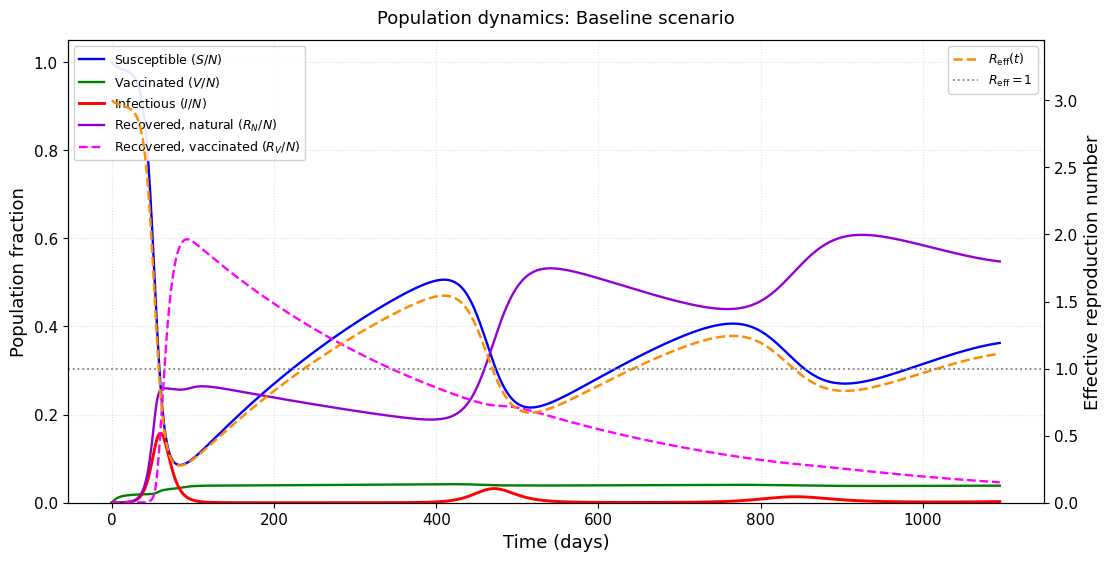

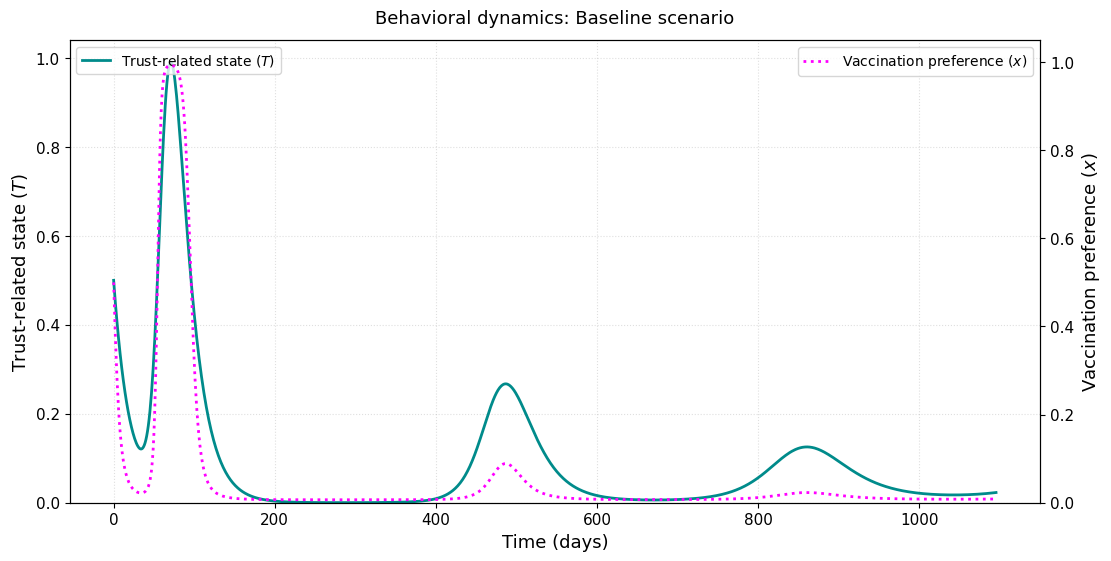

Generating: Reduced behavioral response ($\lambda=0.1$)


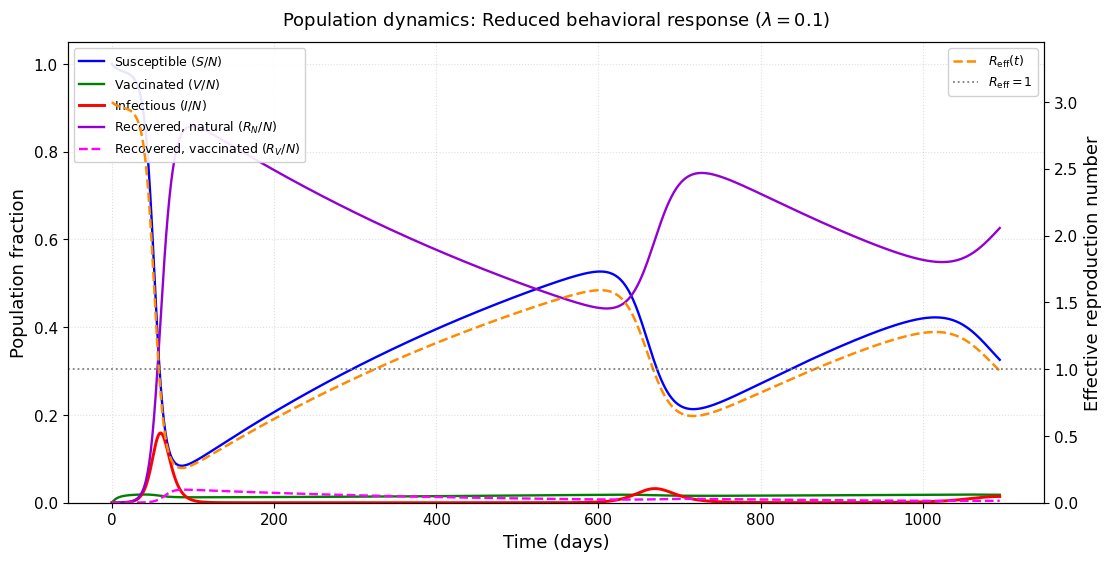

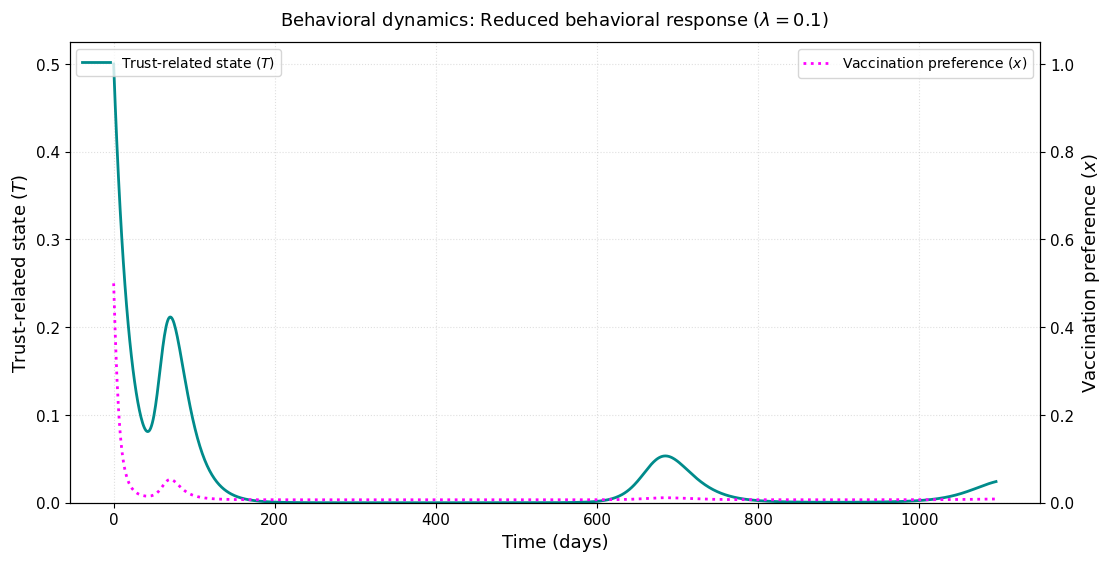

Generating: Increased behavioral-state decay ($\mu=0.2$)


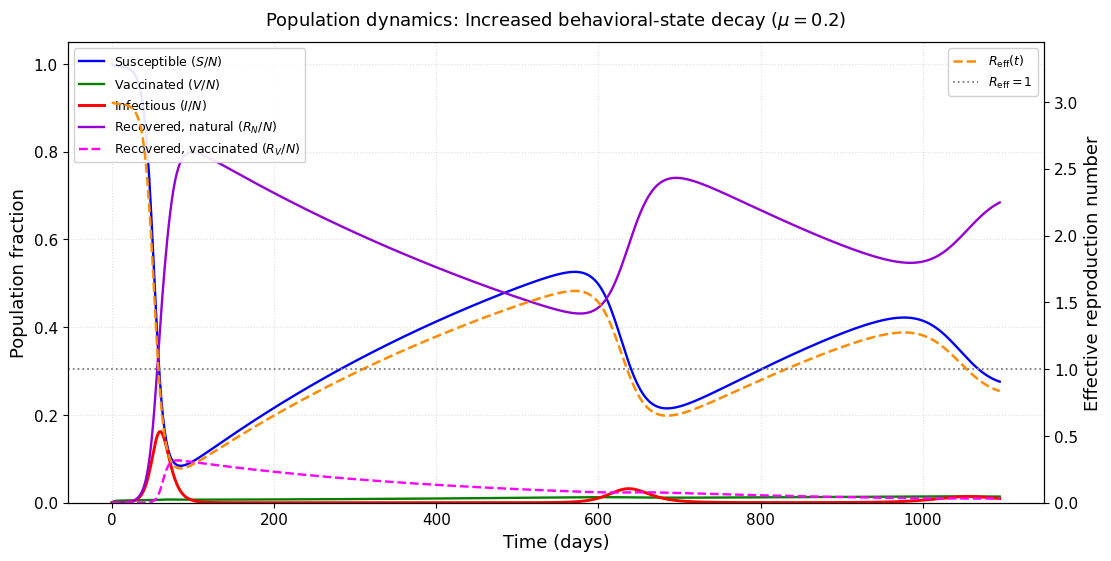

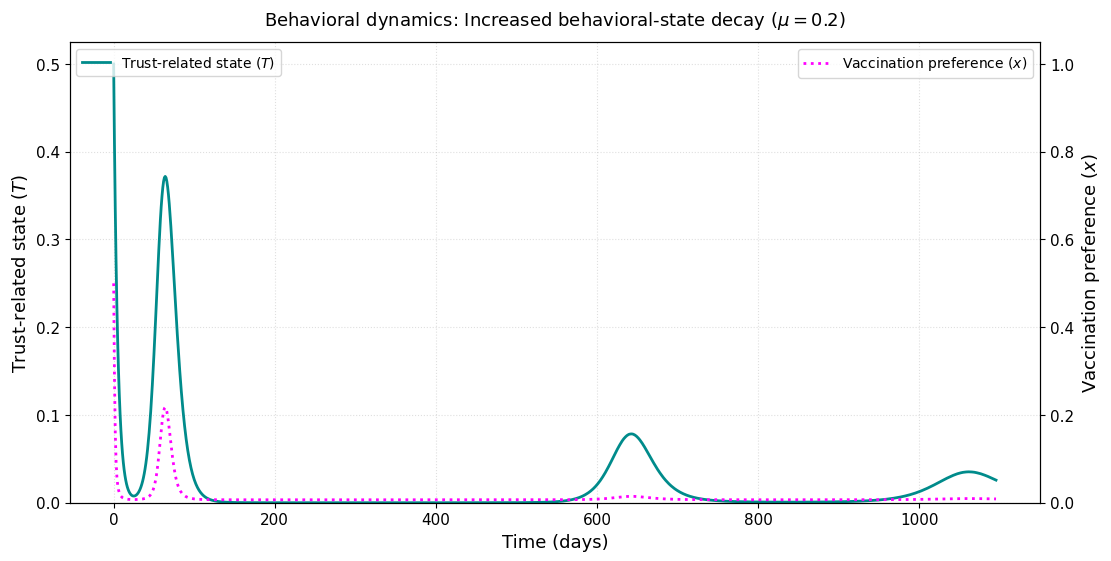

Generating: Lower vaccine efficacy ($\epsilon=0.4$)


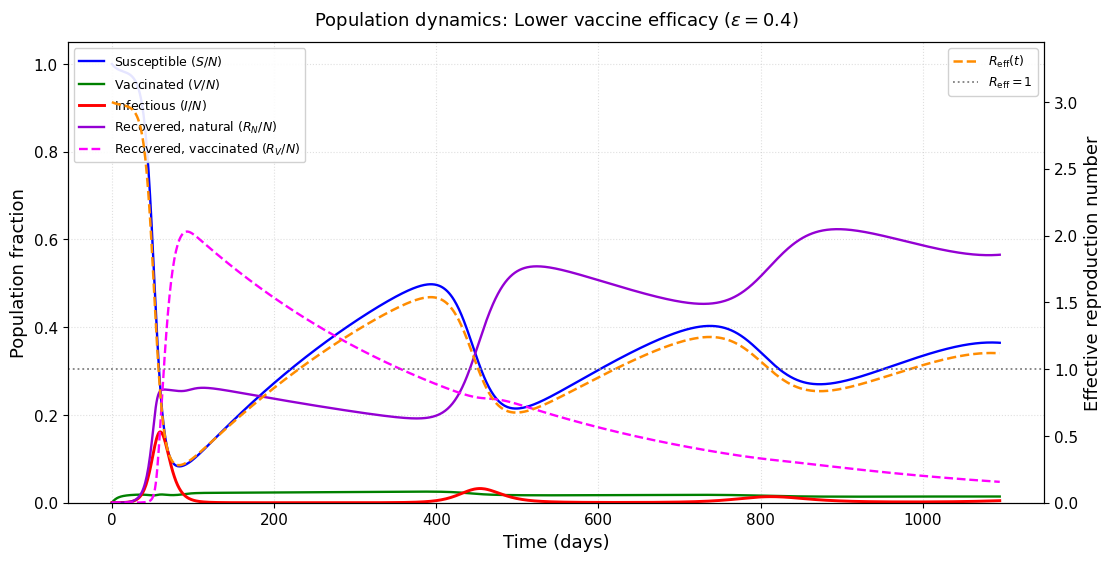

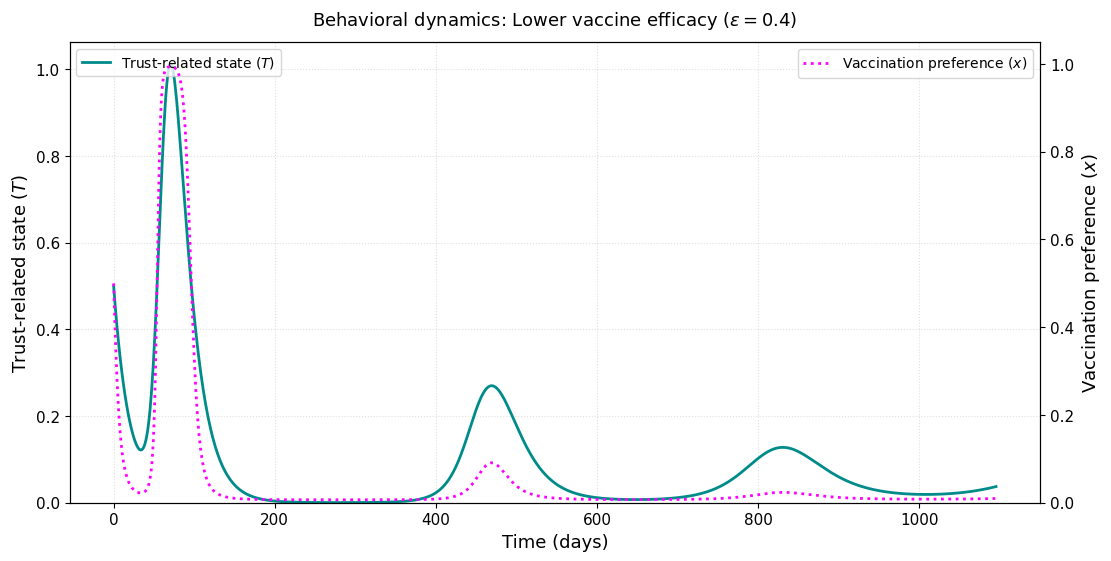

Generating: Higher initial behavioral state ($T(0)=0.9$)


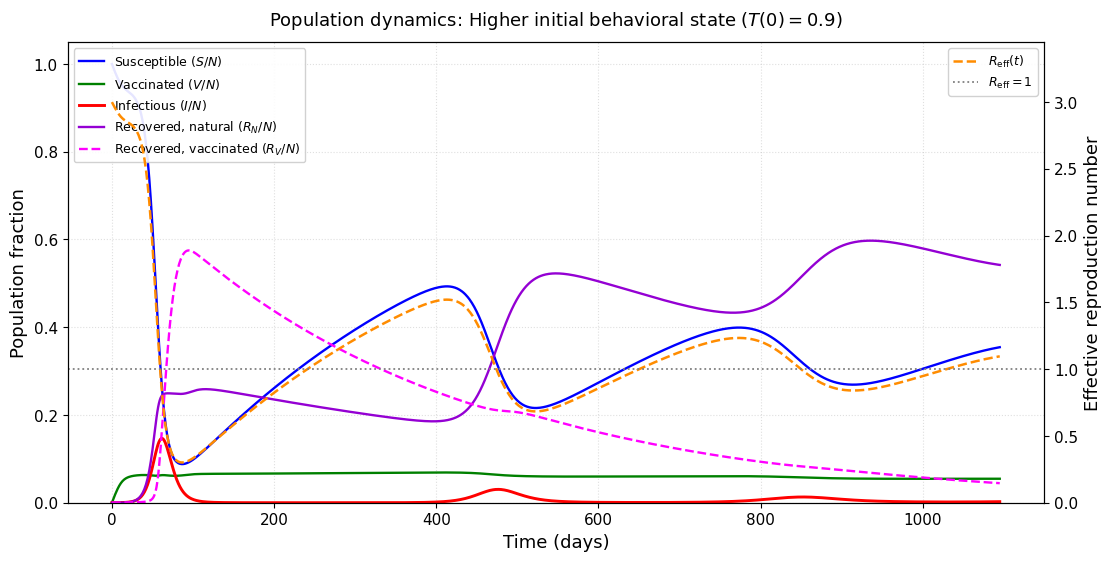

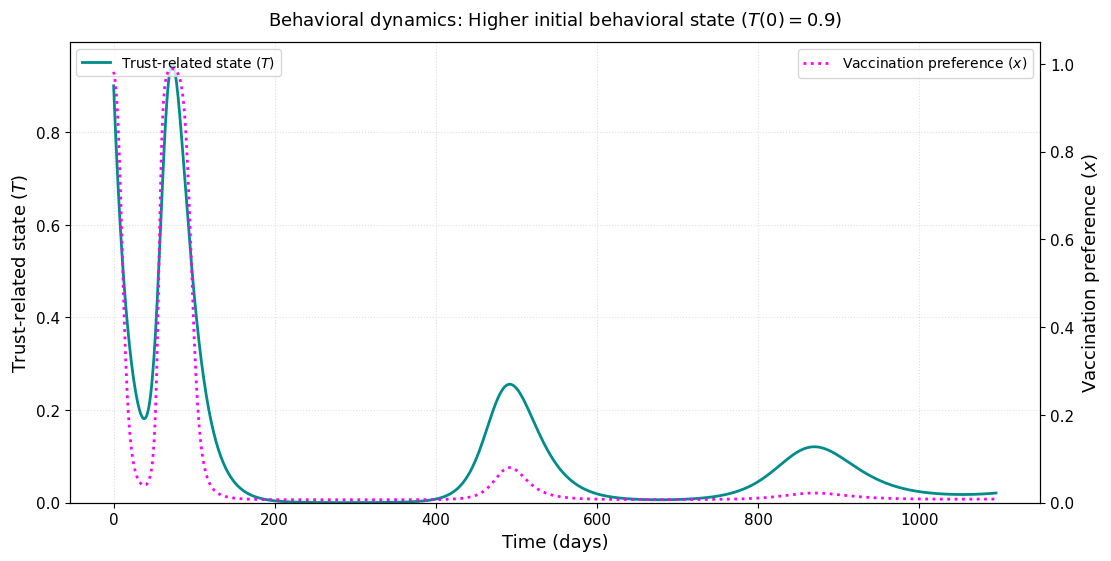


All figures generated successfully.
Saved 10 PNG and 10 PDF figures in: /content/minor4_revised_figures


In [1]:

import numpy as np
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp
from scipy.special import expit
from pathlib import Path

# ============================================================
# 1. FIGURE SETTINGS
# ============================================================

OUT = Path("minor4_revised_figures")
OUT.mkdir(exist_ok=True)

plt.rcParams.update({
    "font.size": 12,
    "axes.labelsize": 13,
    "axes.titlesize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 10,
    "savefig.dpi": 400
})


# ============================================================
# 2. ORIGINAL SEVIRS-TRUST MODEL
# ============================================================

def model(t, y, params):

    S, V, E, I, R_N, R_V, T = y

    N = params["N"]

    x = expit(
        params["k"] * (T - params["T_0"])
    )

    d_S = (
        -params["beta"] * S * I / N
        -params["phi"] * x * S
        +params["omega_N"] * R_N
        +params["omega_V"] * R_V
    )

    d_V = (
        params["phi"] * x * S
        -(1 - params["epsilon"])
        * params["beta"] * V * I / N
    )

    d_E = (
        params["beta"] * S * I / N
        +(1 - params["epsilon"])
        * params["beta"] * V * I / N
        -params["sigma"] * E
    )

    d_I = (
        params["sigma"] * E
        -params["gamma"] * I
    )

    d_RN = (
        (1 - x) * params["gamma"] * I
        -params["omega_N"] * R_N
    )

    d_RV = (
        x * params["gamma"] * I
        -params["omega_V"] * R_V
    )

    d_T = (
        params["lambda_trust"] * I / N
        -params["mu"] * T
    )

    return [
        d_S, d_V, d_E, d_I,
        d_RN, d_RV, d_T
    ]


# ============================================================
# 3. SAVE FIGURES
# ============================================================

def save_figure(fig, stem):

    fig.savefig(
        OUT / f"{stem}.png",
        dpi=400,
        bbox_inches="tight",
        pad_inches=0.15
    )

    fig.savefig(
        OUT / f"{stem}.pdf",
        bbox_inches="tight",
        pad_inches=0.15
    )

    plt.show()
    plt.close(fig)


# ============================================================
# 4. RUN SIMULATION AND GENERATE BOTH PANELS
# ============================================================

def run_simulation(title, stem, params, y0, t_span):

    t_eval = np.arange(
        t_span[0],
        t_span[1] + 1,
        1.0
    )

    sol = solve_ivp(
        model,
        t_span,
        y0,
        args=(params,),
        method="RK45",
        t_eval=t_eval,
        rtol=1e-3,
        atol=1e-6
    )

    if not sol.success:
        raise RuntimeError(sol.message)

    t = sol.t

    S, V, E, I, R_N, R_V, T = sol.y

    N = params["N"]

    x = expit(
        params["k"] * (T - params["T_0"])
    )

    R_eff = (
        params["beta"] / params["gamma"]
    ) * (
        S / N
        +(1 - params["epsilon"]) * V / N
    )

    # ========================================================
    # FIGURE A: POPULATION DYNAMICS
    # ========================================================

    fig, ax1 = plt.subplots(
        figsize=(11, 5.5),
        constrained_layout=True
    )

    ax1.set_title(
        f"Population dynamics: {title}",
        pad=12
    )

    ax1.set_xlabel("Time (days)")
    ax1.set_ylabel("Population fraction")

    population_curves = [
        (S, "Susceptible ($S/N$)", "blue", "-", 1.7),
        (V, "Vaccinated ($V/N$)", "green", "-", 1.7),
        (I, "Infectious ($I/N$)", "red", "-", 2.1),
        (R_N, "Recovered, natural ($R_N/N$)",
         "darkviolet", "-", 1.7),
        (R_V, "Recovered, vaccinated ($R_V/N$)",
         "magenta", "--", 1.7)
    ]

    for values, label, color, style, lw in population_curves:

        ax1.plot(
            t,
            values / N,
            label=label,
            color=color,
            linestyle=style,
            linewidth=lw
        )

    ax1.set_ylim(0, 1.05)

    ax1.grid(
        True,
        linestyle=":",
        alpha=0.4
    )

    # Secondary axis for effective reproduction number

    ax2 = ax1.twinx()

    ax2.plot(
        t,
        R_eff,
        label=r"$R_{\mathrm{eff}}(t)$",
        color="darkorange",
        linestyle="--",
        linewidth=1.8
    )

    ax2.axhline(
        1,
        color="gray",
        linestyle=":",
        linewidth=1.3,
        label=r"$R_{\mathrm{eff}}=1$"
    )

    ax2.set_ylabel(
        "Effective reproduction number"
    )

    ax2.set_ylim(
        0,
        max(1.2, float(np.max(R_eff)) * 1.15)
    )

    ax1.legend(
        loc="upper left",
        fontsize=9,
        framealpha=0.9
    )

    ax2.legend(
        loc="upper right",
        fontsize=9,
        framealpha=0.9
    )

    save_figure(
        fig,
        stem + "_population"
    )

    # ========================================================
    # FIGURE B: BEHAVIORAL DYNAMICS
    # ========================================================

    fig, ax3 = plt.subplots(
        figsize=(11, 5.5),
        constrained_layout=True
    )

    ax3.set_title(
        f"Behavioral dynamics: {title}",
        pad=12
    )

    ax3.set_xlabel("Time (days)")

    ax3.set_ylabel(
        r"Trust-related state ($T$)"
    )

    ax3.plot(
        t,
        T,
        label=r"Trust-related state ($T$)",
        color="darkcyan",
        linewidth=2
    )

    ax3.set_ylim(bottom=0)

    ax3.grid(
        True,
        linestyle=":",
        alpha=0.4
    )

    # Secondary axis for vaccination preference

    ax4 = ax3.twinx()

    ax4.set_ylabel(
        r"Vaccination preference ($x$)"
    )

    ax4.plot(
        t,
        x,
        label=r"Vaccination preference ($x$)",
        color="magenta",
        linestyle=":",
        linewidth=2
    )

    ax4.set_ylim(0, 1.05)

    ax3.legend(
        loc="upper left",
        fontsize=10
    )

    ax4.legend(
        loc="upper right",
        fontsize=10
    )

    save_figure(
        fig,
        stem + "_behavior"
    )


# ============================================================
# 5. BASELINE PARAMETERS
# ============================================================

N_total = 1_000_000

y0_base = [
    N_total - 100,
    0,
    0,
    100,
    0,
    0,
    0.5
]

t_span = (0, 1095)

default_params = {
    "N": N_total,
    "beta": 0.6,
    "gamma": 0.2,
    "sigma": 0.25,
    "phi": 0.005,
    "epsilon": 0.8,
    "omega_N": 1 / (365 * 2),
    "omega_V": 1 / 365,
    "lambda_trust": 0.5,
    "mu": 0.05,
    "k": 10,
    "T_0": 0.5
}


# ============================================================
# 6. FIVE SIMULATION SCENARIOS
# ============================================================

cases = []

# Scenario 1: Baseline

cases.append((
    "Baseline scenario",
    "baseline",
    default_params.copy(),
    y0_base
))

# Scenario 2: Reduced behavioral response

p = default_params.copy()
p["lambda_trust"] = 0.1

cases.append((
    r"Reduced behavioral response ($\lambda=0.1$)",
    "Reduced behavioral response",
    p,
    y0_base
))

# Scenario 3: Increased behavioral-state decay

p = default_params.copy()
p["mu"] = 0.2

cases.append((
    r"Increased behavioral-state decay ($\mu=0.2$)",
    "Increased behavioral-state decay",
    p,
    y0_base
))

# Scenario 4: Lower vaccine efficacy

p = default_params.copy()
p["epsilon"] = 0.4

cases.append((
    r"Lower vaccine efficacy ($\epsilon=0.4$)",
    "lower_vaccine_efficacy",
    p,
    y0_base
))

# Scenario 5: Higher initial behavioral state

y0_high_trust = [
    N_total - 100,
    0,
    0,
    100,
    0,
    0,
    0.9
]

cases.append((
    r"Higher initial behavioral state ($T(0)=0.9$)",
    "higher_initial_behavioral state",
    default_params.copy(),
    y0_high_trust
))


# ============================================================
# 7. GENERATE ALL FIGURES
# ============================================================

for title, stem, params, y0 in cases:

    print("Generating:", title)

    run_simulation(
        title,
        stem,
        params,
        y0,
        t_span
    )

print("\nAll figures generated successfully.")

print(
    "Saved 10 PNG and 10 PDF figures in:",
    OUT.resolve()
)


POSITIVE ENDEMIC EQUILIBRIA
Lower equilibrium:  I* = 57.538116
Higher equilibrium: I* = 4358.379856

REPRESENTATIVE TRAJECTORIES
p=0.00 | I(3000)=4.434145e+03 | I(12000)=4.358389e+03
p=0.60 | I(3000)=3.735744e+03 | I(12000)=4.352674e+03
p=0.80 | I(3000)=1.702223e+03 | I(12000)=4.322182e+03
p=0.90 | I(3000)=6.788042e-25 | I(12000)=2.839748e-122

Running coarse scan...
Completed 20/101
Completed 40/101
Completed 60/101
Completed 80/101
Completed 100/101

Running refined scan...
Completed 40/161
Completed 80/161
Completed 120/161
Completed 160/161

FINITE-TIME TRANSITION ESTIMATE
Transition bracket: 0.82550 to 0.82600
Approximate finite-time transition: p = 0.82575


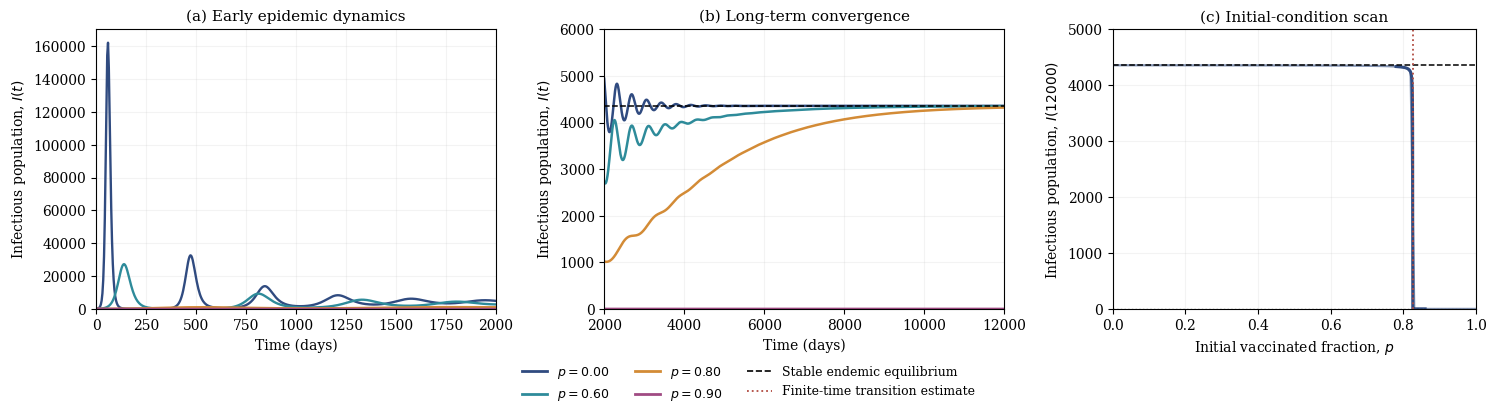


Figure saved successfully.
bistability_three_panel_final.pdf
bistability_three_panel_final.png


In [ ]:

import numpy as np
import matplotlib.pyplot as plt

from matplotlib.lines import Line2D
from scipy.integrate import solve_ivp
from scipy.optimize import brentq


# ============================================================
# 1. BASELINE MODEL PARAMETERS
# ============================================================

N = 1_000_000

beta = 0.6
phi = 0.005
epsilon = 0.8
sigma = 0.25
gamma = 0.2

omega_V = 1 / 365
omega_N = 1 / 730

lam = 0.5
mu = 0.05
k = 10
T_c = 0.5

I0 = 100

# Extended horizon to detect delayed epidemic resurgence
T_END = 12000

RTOL = 1e-9
ATOL = 1e-10


# ============================================================
# 2. SEVEN-COMPARTMENT EPIDEMIOLOGICAL MODEL
# ============================================================

def vaccination_preference(T):
    z = np.clip(k * (T - T_c), -700, 700)
    return 1.0 / (1.0 + np.exp(-z))


def model(t, y):
    S, V, E, I, RN, RV, T = y

    x = vaccination_preference(T)

    infection_S = beta * S * I / N
    infection_V = (1 - epsilon) * beta * V * I / N

    dS = (
        -infection_S
        - phi * x * S
        + omega_N * RN
        + omega_V * RV
    )

    dV = phi * x * S - infection_V

    dE = infection_S + infection_V - sigma * E

    dI = sigma * E - gamma * I

    dRN = (1 - x) * gamma * I - omega_N * RN

    dRV = x * gamma * I - omega_V * RV

    dT = lam * I / N - mu * T

    return [dS, dV, dE, dI, dRN, dRV, dT]


# ============================================================
# 3. INITIAL CONDITIONS
# ============================================================

def initial_conditions(p):
    """
    p: initial vaccinated fraction among the
       initially uninfected population.
    """

    if not 0 <= p <= 1:
        raise ValueError("p must be between 0 and 1.")

    return np.array([
        (1 - p) * (N - I0),
        p * (N - I0),
        0.0,
        I0,
        0.0,
        0.0,
        0.0
    ], dtype=float)


def simulate(p, t_end=T_END, t_eval=None):
    sol = solve_ivp(
        model,
        (0, t_end),
        initial_conditions(p),
        method="DOP853",
        t_eval=t_eval,
        rtol=RTOL,
        atol=ATOL,
        max_step=10
    )

    if not sol.success:
        raise RuntimeError(
            f"Integration failed for p={p}: {sol.message}"
        )

    return sol


# ============================================================
# 4. ENDEMIC EQUILIBRIUM CALCULATION
# ============================================================

def H(x):
    return (
        1
        + gamma / sigma
        + gamma * (
            (1 - x) / omega_N
            + x / omega_V
        )
    )


def equilibrium_residual(i):
    x = vaccination_preference((lam / mu) * i)

    A = beta * H(x)

    B = (
        phi * x * H(x)
        + gamma - beta
    )

    C = phi * x * (
        gamma / ((1 - epsilon) * beta) - 1
    )

    return A * i**2 + B * i + C


i_grid = np.logspace(-10, -0.01, 5000)

roots = []

for left, right in zip(i_grid[:-1], i_grid[1:]):

    f_left = equilibrium_residual(left)
    f_right = equilibrium_residual(right)

    if f_left * f_right < 0:

        root = brentq(
            equilibrium_residual,
            left,
            right,
            xtol=1e-14
        )

        if not any(
            abs(root - r) < 1e-9
            for r in roots
        ):
            roots.append(root)

roots = sorted(roots)

if len(roots) < 2:
    raise RuntimeError(
        "Expected two positive endemic equilibria."
    )

I_UNSTABLE = N * roots[0]
I_ENDEMIC = N * roots[-1]

print("=" * 65)
print("POSITIVE ENDEMIC EQUILIBRIA")
print("=" * 65)

print(f"Lower equilibrium:  I* = {I_UNSTABLE:.6f}")
print(f"Higher equilibrium: I* = {I_ENDEMIC:.6f}")


# ============================================================
# 5. REPRESENTATIVE INFECTION TRAJECTORIES
# ============================================================

selected_p = [0.00, 0.60, 0.80, 0.90]

t_eval = np.linspace(0, T_END, 3001)

trajectories = {}

print("\n" + "=" * 65)
print("REPRESENTATIVE TRAJECTORIES")
print("=" * 65)

for p in selected_p:

    sol = simulate(p, t_eval=t_eval)

    trajectories[p] = sol

    I_3000 = np.interp(
        3000,
        sol.t,
        sol.y[3]
    )

    I_12000 = sol.y[3, -1]

    print(
    f"p={p:.2f} | "
    f"I(3000)={I_3000:.6e} | "
    f"I(12000)={I_12000:.6e}"
)


# ============================================================
# 6. COARSE INITIAL-CONDITION SCAN
# ============================================================

p_scan = np.linspace(0, 1, 101)

I_final = np.zeros(len(p_scan))

print("\nRunning coarse scan...")

for j, p in enumerate(p_scan):

    sol = simulate(p)

    I_final[j] = max(
        0.0,
        sol.y[3, -1]
    )

    if (j + 1) % 20 == 0:
        print(
            f"Completed {j + 1}/{len(p_scan)}"
        )


# ============================================================
# 7. REFINED INITIAL-CONDITION SCAN
# ============================================================

# Focus on the transition visible in the coarse scan.

p_fine = np.linspace(0.78, 0.86, 161)

I_fine = np.zeros(len(p_fine))

print("\nRunning refined scan...")

for j, p in enumerate(p_fine):

    sol = simulate(p)

    I_fine[j] = max(
        0.0,
        sol.y[3, -1]
    )

    if (j + 1) % 40 == 0:
        print(
            f"Completed {j + 1}/{len(p_fine)}"
        )


# ============================================================
# 8. ESTIMATE FINITE-TIME TRANSITION
# ============================================================

# The midpoint of the stable endemic infection level
# is used only to classify the finite-time scan.

classification_level = I_ENDEMIC / 2

endemic_mask = I_fine > classification_level

transition_indices = np.where(
    np.diff(endemic_mask.astype(int)) != 0
)[0]

print("\n" + "=" * 65)
print("FINITE-TIME TRANSITION ESTIMATE")
print("=" * 65)

if len(transition_indices) == 0:

    print(
        "No transition detected in the refined interval."
    )

    p_transition = np.nan

else:

    for j in transition_indices:

        p_left = p_fine[j]
        p_right = p_fine[j + 1]

        print(
            f"Transition bracket: "
            f"{p_left:.5f} to {p_right:.5f}"
        )

    # Use the first detected transition for plotting.
    j = transition_indices[0]

    p_transition = (
        p_fine[j] + p_fine[j + 1]
    ) / 2

    print(
        f"Approximate finite-time transition: "
        f"p = {p_transition:.5f}"
    )


# ============================================================
# 9. PUBLICATION FIGURE SETTINGS
# ============================================================

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.labelsize": 10,
    "axes.titlesize": 11,
    "legend.fontsize": 9,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.dpi": 600
})

colors = {
    0.00: "#304B80",
    0.60: "#2E8B9A",
    0.80: "#D38B36",
    0.90: "#A04B83"
}

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4.3),
    gridspec_kw={
        "width_ratios": [1.1, 1.1, 1]
    }
)

# ============================================================
# PANEL (a): EARLY EPIDEMIC DYNAMICS
# ============================================================

ax = axes[0]

for p in selected_p:

    sol = trajectories[p]

    ax.plot(
        sol.t,
        np.maximum(sol.y[3], 0),
        color=colors[p],
        linewidth=1.7
    )

ax.set_xlim(0, 2000)
ax.set_ylim(bottom=0)

ax.set_xlabel("Time (days)")
ax.set_ylabel(r"Infectious population, $I(t)$")

ax.set_title("(a) Early epidemic dynamics")

ax.grid(alpha=0.15)


# ============================================================
# PANEL (b): LONG-TERM CONVERGENCE
# ============================================================

ax = axes[1]

for p in selected_p:

    sol = trajectories[p]

    ax.plot(
        sol.t,
        np.maximum(sol.y[3], 0),
        color=colors[p],
        linewidth=1.8
    )

ax.axhline(
    I_ENDEMIC,
    color="black",
    linestyle="--",
    linewidth=1.1
)

ax.set_xlim(2000, T_END)
ax.set_ylim(0, 6000)

ax.set_xlabel("Time (days)")
ax.set_ylabel(r"Infectious population, $I(t)$")

ax.set_title("(b) Long-term convergence")

ax.grid(alpha=0.15)


# ============================================================
# PANEL (c): INITIAL-CONDITION SCAN
# ============================================================

ax = axes[2]

# Coarse scan over the complete initial-condition interval.
ax.plot(
    p_scan,
    I_final,
    color="#304B80",
    linewidth=1.6,
    alpha=0.6
)

# Refined scan near the transition.
ax.plot(
    p_fine,
    I_fine,
    color="#304B80",
    linewidth=2.2
)

ax.axhline(
    I_ENDEMIC,
    color="black",
    linestyle="--",
    linewidth=1.1
)

ax.axhline(
    0,
    color="gray",
    linestyle=":",
    linewidth=1.0
)

# Mark approximate finite-time transition.
if np.isfinite(p_transition):

    ax.axvline(
        p_transition,
        color="#B14A40",
        linestyle=":",
        linewidth=1.3
    )

ax.set_xlim(0, 1)
ax.set_ylim(0, 5000)

ax.set_xlabel(
    r"Initial vaccinated fraction, $p$"
)

ax.set_ylabel(
    rf"Infectious population, $I({T_END})$"
)

ax.set_title("(c) Initial-condition scan")

ax.grid(alpha=0.15)


# ============================================================
# 10. SHARED LEGEND AND EXPORT
# ============================================================

handles = [
    Line2D(
        [0], [0],
        color=colors[p],
        linewidth=2,
        label=fr"$p={p:.2f}$"
    )
    for p in selected_p
]

handles.append(
    Line2D(
        [0], [0],
        color="black",
        linestyle="--",
        linewidth=1.2,
        label="Stable endemic equilibrium"
    )
)

if np.isfinite(p_transition):

    handles.append(
        Line2D(
            [0], [0],
            color="#B14A40",
            linestyle=":",
            linewidth=1.3,
            label="Finite-time transition estimate"
        )
    )

fig.legend(
    handles=handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.005),
    ncol=3,
    frameon=False
)

fig.subplots_adjust(
    left=0.065,
    right=0.985,
    top=0.90,
    bottom=0.25,
    wspace=0.28
)

fig.savefig(
    "bistability_three_panel_final.pdf",
    bbox_inches="tight",
    pad_inches=0.12
)

fig.savefig(
    "bistability_three_panel_final.png",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.12
)

plt.show()

print("\nFigure saved successfully.")
print("bistability_three_panel_final.pdf")
print("bistability_three_panel_final.png")


POSITIVE ENDEMIC EQUILIBRIA
Lower equilibrium:  I* = 57.538116
Higher equilibrium: I* = 4358.379856

REPRESENTATIVE TRAJECTORIES
p=0.00 | I(3000)=4.434145e+03 | I(12000)=4.358389e+03
p=0.60 | I(3000)=3.735744e+03 | I(12000)=4.352674e+03
p=0.80 | I(3000)=1.702223e+03 | I(12000)=4.322182e+03
p=0.90 | I(3000)=6.788042e-25 | I(12000)=2.839748e-122

Running coarse scan...
Completed 20/101
Completed 40/101
Completed 60/101
Completed 80/101
Completed 100/101

Running refined scan...
Completed 40/161
Completed 80/161
Completed 120/161
Completed 160/161

FINITE-TIME TRANSITION ESTIMATE
Transition bracket: 0.82550 to 0.82600
Approximate finite-time transition: p = 0.82575


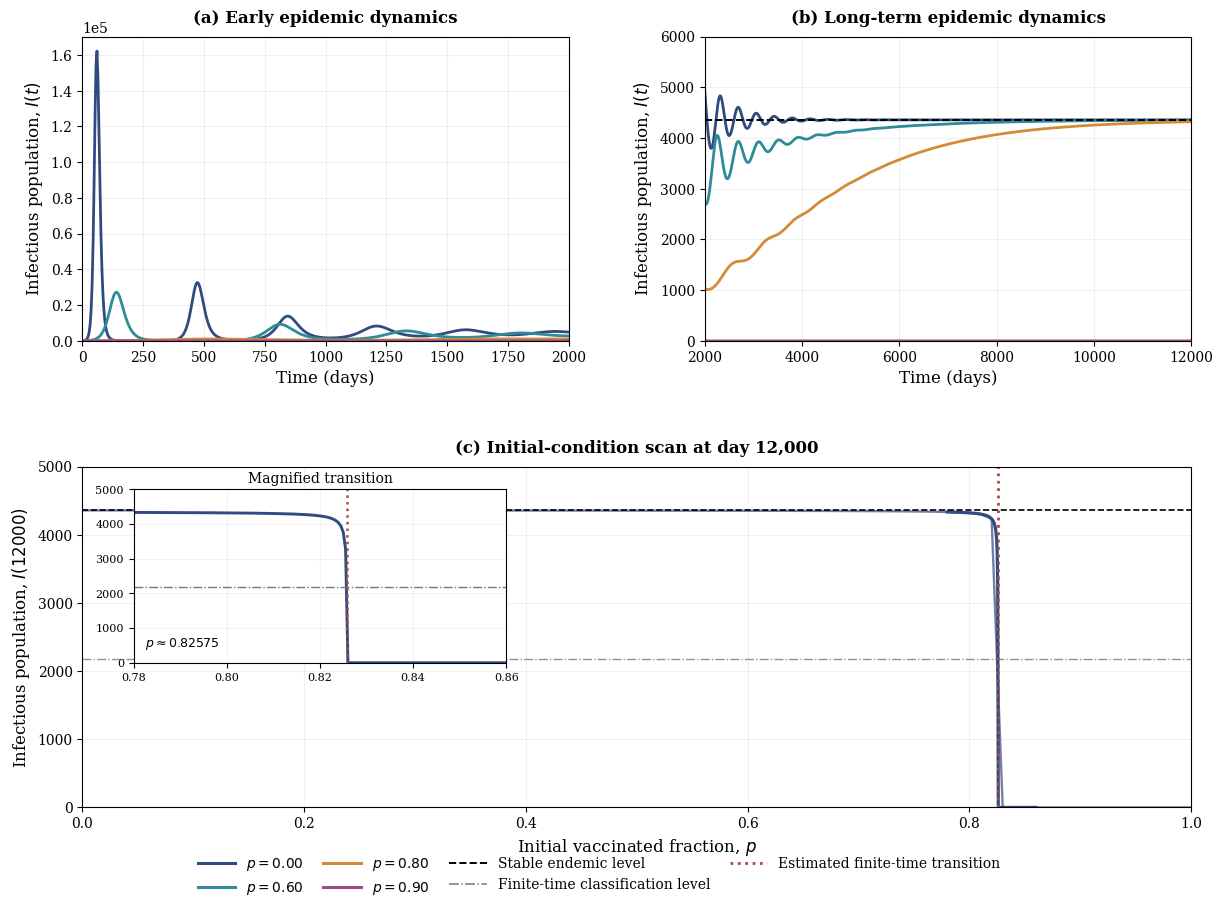

Saved bistability_three_panel_revised.pdf and .png


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.lines import Line2D
from scipy.integrate import solve_ivp
from scipy.optimize import brentq


# ============================================================
# 1. BASELINE MODEL PARAMETERS
# ============================================================

N = 1_000_000

beta = 0.6
phi = 0.005
epsilon = 0.8
sigma = 0.25
gamma = 0.2

omega_V = 1 / 365
omega_N = 1 / 730

lam = 0.5
mu = 0.05
k = 10
T_c = 0.5

I0 = 100

# Extended horizon to detect delayed epidemic resurgence
T_END = 12000

RTOL = 1e-9
ATOL = 1e-10


# ============================================================
# 2. SEVEN-COMPARTMENT EPIDEMIOLOGICAL MODEL
# ============================================================

def vaccination_preference(T):
    z = np.clip(k * (T - T_c), -700, 700)
    return 1.0 / (1.0 + np.exp(-z))


def model(t, y):
    S, V, E, I, RN, RV, T = y

    x = vaccination_preference(T)

    infection_S = beta * S * I / N
    infection_V = (1 - epsilon) * beta * V * I / N

    dS = (
        -infection_S
        - phi * x * S
        + omega_N * RN
        + omega_V * RV
    )

    dV = phi * x * S - infection_V

    dE = infection_S + infection_V - sigma * E

    dI = sigma * E - gamma * I

    dRN = (1 - x) * gamma * I - omega_N * RN

    dRV = x * gamma * I - omega_V * RV

    dT = lam * I / N - mu * T

    return [dS, dV, dE, dI, dRN, dRV, dT]

# ============================================================
# 3. INITIAL CONDITIONS
# ============================================================

def initial_conditions(p):
    """
    p: initial vaccinated fraction among the
       initially uninfected population.
    """

    if not 0 <= p <= 1:
        raise ValueError("p must be between 0 and 1.")

    return np.array([
        (1 - p) * (N - I0),
        p * (N - I0),
        0.0,
        I0,
        0.0,
        0.0,
        0.0
    ], dtype=float)


def simulate(p, t_end=T_END, t_eval=None):
    sol = solve_ivp(
        model,
        (0, t_end),
        initial_conditions(p),
        method="DOP853",
        t_eval=t_eval,
        rtol=RTOL,
        atol=ATOL,
        max_step=10
    )

    if not sol.success:
        raise RuntimeError(
            f"Integration failed for p={p}: {sol.message}"
        )

    return sol


# ============================================================
# 4. ENDEMIC EQUILIBRIUM CALCULATION
# ============================================================

def H(x):
    return (
        1
        + gamma / sigma
        + gamma * (
            (1 - x) / omega_N
            + x / omega_V
        )
    )


def equilibrium_residual(i):
    x = vaccination_preference((lam / mu) * i)

    A = beta * H(x)

    B = (
        phi * x * H(x)
        + gamma - beta
    )

    C = phi * x * (
        gamma / ((1 - epsilon) * beta) - 1
    )

    return A * i**2 + B * i + C


i_grid = np.logspace(-10, -0.01, 5000)

roots = []

for left, right in zip(i_grid[:-1], i_grid[1:]):

    f_left = equilibrium_residual(left)
    f_right = equilibrium_residual(right)

    if f_left * f_right < 0:

        root = brentq(
            equilibrium_residual,
            left,
            right,
            xtol=1e-14
        )
        if not any(
            abs(root - r) < 1e-9
            for r in roots
        ):
            roots.append(root)

roots = sorted(roots)

if len(roots) < 2:
    raise RuntimeError(
        "Expected two positive endemic equilibria."
    )

I_UNSTABLE = N * roots[0]
I_ENDEMIC = N * roots[-1]

print("=" * 65)
print("POSITIVE ENDEMIC EQUILIBRIA")
print("=" * 65)

print(f"Lower equilibrium:  I* = {I_UNSTABLE:.6f}")
print(f"Higher equilibrium: I* = {I_ENDEMIC:.6f}")


# ============================================================
# 5. REPRESENTATIVE INFECTION TRAJECTORIES
# ============================================================

selected_p = [0.00, 0.60, 0.80, 0.90]

t_eval = np.linspace(0, T_END, 3001)

trajectories = {}

print("\n" + "=" * 65)
print("REPRESENTATIVE TRAJECTORIES")
print("=" * 65)

for p in selected_p:

    sol = simulate(p, t_eval=t_eval)

    trajectories[p] = sol

    I_3000 = np.interp(
        3000,
        sol.t,
        sol.y[3]
    )

    I_12000 = sol.y[3, -1]

    print(
    f"p={p:.2f} | "
    f"I(3000)={I_3000:.6e} | "
    f"I(12000)={I_12000:.6e}"
)


# ============================================================
# 6. COARSE INITIAL-CONDITION SCAN
# ============================================================

p_scan = np.linspace(0, 1, 101)

I_final = np.zeros(len(p_scan))

print("\nRunning coarse scan...")

for j, p in enumerate(p_scan):

    sol = simulate(p)

    I_final[j] = max(
        0.0,
        sol.y[3, -1]
    )

    if (j + 1) % 20 == 0:
        print(
            f"Completed {j + 1}/{len(p_scan)}"
        )


# ============================================================
# 7. REFINED INITIAL-CONDITION SCAN
# ============================================================

# Focus on the transition visible in the coarse scan.

p_fine = np.linspace(0.78, 0.86, 161)

I_fine = np.zeros(len(p_fine))

print("\nRunning refined scan...")

for j, p in enumerate(p_fine):

    sol = simulate(p)

    I_fine[j] = max(
        0.0,
        sol.y[3, -1]
    )

    if (j + 1) % 40 == 0:
        print(
            f"Completed {j + 1}/{len(p_fine)}"
        )


# ============================================================
# 8. ESTIMATE FINITE-TIME TRANSITION
# ============================================================

# The midpoint of the stable endemic infection level
# is used only to classify the finite-time scan.

classification_level = I_ENDEMIC / 2

endemic_mask = I_fine > classification_level

transition_indices = np.where(
    np.diff(endemic_mask.astype(int)) != 0
)[0]

print("\n" + "=" * 65)
print("FINITE-TIME TRANSITION ESTIMATE")
print("=" * 65)

if len(transition_indices) == 0:

    print(
        "No transition detected in the refined interval."
    )

    p_transition = np.nan

else:

    for j in transition_indices:

        p_left = p_fine[j]
        p_right = p_fine[j + 1]

        print(
            f"Transition bracket: "
            f"{p_left:.5f} to {p_right:.5f}"
        )

    # Use the first detected transition for plotting.
    j = transition_indices[0]

    p_transition = (
        p_fine[j] + p_fine[j + 1]
    ) / 2

    print(
        f"Approximate finite-time transition: "
        f"p = {p_transition:.5f}"
    )

# ============================================================
# 9. REVISED PUBLICATION FIGURE: 2 PANELS + WIDE SCAN
# ============================================================
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset
from matplotlib.ticker import MultipleLocator, ScalarFormatter

plt.rcParams.update({
    "font.family": "serif", "font.size": 11,
    "axes.labelsize": 12, "axes.titlesize": 12,
    "xtick.labelsize": 10, "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "pdf.fonttype": 42, "ps.fonttype": 42,
    "savefig.dpi": 600,
})

colors = {
    0.00: "#304B80", 0.60: "#2E8B9A",
    0.80: "#D38B36", 0.90: "#A04B83",
}

fig = plt.figure(figsize=(12.6, 9.4), constrained_layout=False)
gs = fig.add_gridspec(
    2, 2, height_ratios=[1, 1.12],
    left=0.09, right=0.97, top=0.94, bottom=0.12,
    hspace=0.39, wspace=0.28,
)
ax_a = fig.add_subplot(gs[0, 0])
ax_b = fig.add_subplot(gs[0, 1])
ax_c = fig.add_subplot(gs[1, :])

# (a) Early dynamics: 0–2000 days.
for p in selected_p:
    sol = trajectories[p]
    ax_a.plot(sol.t, np.maximum(sol.y[3], 0),
              color=colors[p], linewidth=2.0, label=fr"$p={p:.2f}$")
ax_a.set_xlim(0, 2000)
ax_a.set_ylim(bottom=0)
ax_a.set_xlabel("Time (days)")
ax_a.set_ylabel(r"Infectious population, $I(t)$")
ax_a.set_title("(a) Early epidemic dynamics", fontweight="bold", pad=10)
ax_a.grid(alpha=0.18)
ax_a.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))

# (b) Long-term dynamics: 2000–12000 days.
for p in selected_p:
    sol = trajectories[p]
    ax_b.plot(sol.t, np.maximum(sol.y[3], 0),
              color=colors[p], linewidth=2.0)
ax_b.axhline(I_ENDEMIC, color="black", ls="--", lw=1.4)
ax_b.set_xlim(2000, T_END)
ax_b.set_ylim(0, 6000)
ax_b.set_xlabel("Time (days)")
ax_b.set_ylabel(r"Infectious population, $I(t)$")
ax_b.set_title("(b) Long-term epidemic dynamics", fontweight="bold", pad=10)
ax_b.grid(alpha=0.18)

# (c) Full-width initial-condition scan.
ax_c.plot(p_scan, I_final, color="#304B80", lw=1.7,
          alpha=0.7, label="Coarse scan")
ax_c.plot(p_fine, I_fine, color="#304B80", lw=2.3,
          label="Refined scan")
ax_c.axhline(I_ENDEMIC, color="black", ls="--", lw=1.2)
ax_c.axhline(classification_level, color="#777777", ls="-.",
             lw=1.0, alpha=0.8)
if np.isfinite(p_transition):
    ax_c.axvline(p_transition, color="#B14A40", ls=":", lw=2.0)
ax_c.set_xlim(0, 1)
ax_c.set_ylim(0, 5000)
ax_c.set_xlabel(r"Initial vaccinated fraction, $p$")
ax_c.set_ylabel(rf"Infectious population, $I({T_END})$")
ax_c.set_title("(c) Initial-condition scan at day 12,000",
               fontweight="bold", pad=10)
ax_c.grid(alpha=0.18)

# Magnified transition inset, positioned away from the main transition.
ax_in = inset_axes(ax_c, width="35%", height="53%", loc="upper left",
                   bbox_to_anchor=(0.035, 0.01, 0.96, 0.96),
                   bbox_transform=ax_c.transAxes, borderpad=0.9)
ax_in.plot(p_fine, I_fine, color="#304B80", lw=2.1)
ax_in.axhline(classification_level, color="#777777", ls="-.", lw=1.0)
if np.isfinite(p_transition):
    ax_in.axvline(p_transition, color="#B14A40", ls=":", lw=1.8)
    ax_in.text(0.03, 0.09, fr"$p\approx{p_transition:.5f}$",
               transform=ax_in.transAxes, fontsize=9,
               bbox=dict(facecolor="white", edgecolor="none", alpha=0.85))
ax_in.set_xlim(0.78, 0.86)
ax_in.set_ylim(0, 5000)
ax_in.set_xticks([0.78, 0.80, 0.82, 0.84, 0.86])
ax_in.tick_params(labelsize=8)
ax_in.set_title("Magnified transition", fontsize=10, pad=5)
ax_in.grid(alpha=0.16)

# A single, legible legend for trajectory colors and reference lines.
handles = [
    Line2D([0], [0], color=colors[p], lw=2.2, label=fr"$p={p:.2f}$")
    for p in selected_p
]
handles += [
    Line2D([0], [0], color="black", ls="--", lw=1.4,
           label="Stable endemic level"),
    Line2D([0], [0], color="#777777", ls="-.", lw=1.1,
           label="Finite-time classification level"),
    Line2D([0], [0], color="#B14A40", ls=":", lw=2,
           label="Estimated finite-time transition"),
]
fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 0.012),
           ncol=4, frameon=False, columnspacing=1.4, handlelength=2.7)

fig.savefig("bistability_three_panel_revised.pdf",
            bbox_inches="tight", pad_inches=0.16)
fig.savefig("bistability_three_panel_revised.png", dpi=600,
            bbox_inches="tight", pad_inches=0.16)
plt.show()
print("Saved bistability_three_panel_revised.pdf and .png")
